# Linear model: performance on the eval year

An analysis of the linear model (`models.linear_model`, `docs/linear_model.md`) on the held-out
eval year, 2025-10-20 → 2026-10-20: 1,448 forecast runs, one every 6 hours, each 72 hours long.
The model was selected and fitted on the training years only. The eval year was scored once by
`python -m training.linear_model evaluate`; this notebook breaks that score down. Nothing here
feeds back into the model's choices.

The model is a per-lead Gaussian GLM on the target **speed − last observed speed** (relative to
persistence, no Box-Cox transform), weighted by each run's TIMSE weights. Its inputs are the
final baseline's speed terms (last speed, 27-day and 13.5-day recurrence) plus four regressors:

| Regressor | What it is |
|---|---|
| `ch_cm_at_12h` | coronal-hole area in the central-meridian strip, AIA 193 image 12 h before t0 (falling back to the 18 h, then 24 h image) |
| `density_mean_24h` | proton density, mean of the last 24 h |
| `xray_peak_max_48h` | log peak X-ray flare flux in the last 48 h |
| `b_var_mean_48h` | field variability, mean of the last 48 h |

**This is the shipped model, after the data fixes** (`docs/linear_model.md`, "Data fixes"). An earlier version of this notebook analysed the first fit, and its findings led to them:
- **Despiking:** isolated one-hour glitches are removed from the training speeds before fitting.
- **Submodel:** a run with no coronal-hole image is forecast by a submodel fitted without that regressor, instead of with its median.
- **Re-selection:** the variant search and forward selection were re-run with both fixes. They kept the same first four regressors and dropped F10.7.

It is compared against the **final baseline** (the reference model and current submission) and
**persistence**. The first fit's headline scores are quoted from `docs/linear_model.md` where useful.

1. **Scores:** overall, and how the per-run distribution changes.
2. **By regime:** the run labels of `final_baseline_analysis.ipynb` (CME, stream arrival, quiet wind…).
3. **Bias and level:** does the regression fix the baseline's over-forecast of quiet wind?
4. **Stream arrivals:** does the coronal-hole regressor give arrival timing?
5. **The regressors:** coefficients, contributions, ablation, and the coronal-hole archive gap.
6. **Through the year and the worst runs.**
7. **Findings.**

**Conventions:**
- **Residual** = actual − forecast; negative means the model over-predicted.
- **Ratio** = a run's TIMSE for one model divided by another's for the same run. Below 1, the first model wins.
- **Per-run** scores treat each 72-hour run on its own, as the platform scores each submission.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from feature_engineering.recurrence import last_observed, targets
from models.final_baseline import FinalBaseline, run_timse_weights
from models.linear_model import LinearModel
from training import solar_wind_events as ev
from training.datasets import EVAL_END, TRAIN_END, load_hourly
from training.evaluate import HORIZON, forecast_times, run_timse
from training.linear_model import candidate_table
from training.metrics import timse

plt.rcParams.update(
    {"figure.figsize": (11, 3.5), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3}
)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

MODELS = ["linear_model", "final_baseline", "persistence"]
STYLE = {
    "linear_model": {"color": "#eb6834", "lw": 1.8},
    "final_baseline": {"color": "#2a78d6", "lw": 1.5},
    "persistence": {"color": "#8a8984", "lw": 1.5, "ls": (0, (1, 1.5))},
}
REGIME_COLORS = {
    "CME": "#e34948", "possible CME": "#e87ba4", "stream arrival": "#eda100",
    "fast stream": "#6250d6", "slow wind": "#1baf7a", "intermediate": "#52514e",
}
CME_SPAN = {"color": "#e34948", "alpha": 0.18, "lw": 0}
POSSIBLE_SPAN = {"color": "#e87ba4", "alpha": 0.18, "lw": 0}
GAP_SPAN = {"color": "#6250d6", "alpha": 0.12, "lw": 0}
WIN, LOSE = "#1baf7a", "#6250d6"
lead = np.arange(1, HORIZON + 1)


def model_legend(fig, extra=(), models=MODELS):
    handles = [Line2D([], [], **STYLE[m]) for m in models]
    labels = list(models)
    for handle, label in extra:
        handles.append(handle)
        labels.append(label)
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0),
               ncol=len(handles), frameon=False, fontsize=9)


def fmt(table):
    return table.map(lambda x: f"{x:.3g}" if isinstance(x, float) else x)

## 1. Scores

The linear model is loaded from the shipped asset (fitted on the training years) and run
walk-forward over every eval `t0`. Its regressors are built from the pulled history
(`training.pull_features`) with the live availability rules. As live, a run without a coronal-hole
image goes to the submodel and other missing regressors take their training medians. The batch
forecast is checked against the live `predict()` path on one run, and on one submodel run.

In [2]:
series = load_hourly()
values = series.to_numpy()
t0s = forecast_times()
pos = series.index.get_indexer(t0s)
actual = targets(values, pos)

model = LinearModel.load()
FEATURES = list(model.config.features)
table = candidate_table(t0s)
x = table[FEATURES].to_numpy(dtype=float)
imputed = pd.DataFrame(np.isnan(x), index=t0s, columns=FEATURES)

forecasts = {
    "linear_model": model.forecast(values, pos, x),
    "final_baseline": FinalBaseline.load().forecast(values, pos),
    "persistence": np.repeat(last_observed(values, pos)[:, None], HORIZON, 1),
}
submodel = pd.Series(model.uses_fallback(x), index=t0s)
for i in (700, int(np.flatnonzero(submodel)[10])):
    row = dict(zip(FEATURES, x[i], strict=True))
    assert np.allclose(model.predict(series.iloc[: pos[i]], row), forecasts["linear_model"][i])

residuals = {m: actual - f for m, f in forecasts.items()}
run_scores = pd.DataFrame({m: run_timse(forecasts[m], actual) for m in MODELS}, index=t0s)
vs_base = run_scores["linear_model"] / run_scores["final_baseline"]
vs_pers = run_scores["linear_model"] / run_scores["persistence"]
base_vs_pers = run_scores["final_baseline"] / run_scores["persistence"]

overall = pd.DataFrame({
    m: {
        "pooled TIMSE": timse(actual, forecasts[m]),
        "per-run mean": run_scores[m].mean(),
        "per-run median": run_scores[m].median(),
        "per-run p90": run_scores[m].quantile(0.9),
        "RMSE": float(np.sqrt(np.nanmean(residuals[m] ** 2))),
        "beats persistence": (run_scores[m] < run_scores["persistence"]).mean(),
    }
    for m in MODELS
}).T
print(f"{len(t0s)} runs; linear beats the final baseline in {(vs_base < 1).mean():.0%} of runs")
print("regressors missing (share of runs):", imputed.mean().round(3).to_dict())
print(f"runs forecast by the submodel (no coronal-hole image): {submodel.mean():.1%}")
fmt(overall)

1448 runs; linear beats the final baseline in 64% of runs
regressors missing (share of runs): {'ch_cm_at_12h': 0.193, 'density_mean_24h': 0.005, 'xray_peak_max_48h': 0.0, 'b_var_mean_48h': 0.0}
runs forecast by the submodel (no coronal-hole image): 19.3%


,pooled TIMSE,per-run mean,per-run median,per-run p90,RMSE,beats persistence
linear_model,4.74e+07,2.37e+06,6.76e+05,3.76e+06,102,0.603
final_baseline,5.58e+07,2.59e+06,8.45e+05,3.21e+06,110,0.532
persistence,8.13e+07,5.57e+06,7.76e+05,1.38e+07,110,0


**The per-run distribution.** The per-run mean is what the platform's per-run scoring averages,
and it is set by the worst runs. The table compares the two models' per-run TIMSE at several
quantiles. The scatter puts every run's linear-model TIMSE against the final baseline's: below the
diagonal, the linear model wins.

,linear_model,final_baseline,linear / baseline
p10,1.95e+05,2.48e+05,0.784
p25,3.66e+05,4.39e+05,0.834
p50,6.76e+05,8.45e+05,0.8
p75,1.48e+06,1.64e+06,0.901
p90,3.76e+06,3.21e+06,1.17
p95,6.94e+06,7.99e+06,0.868
p99,3.72e+07,4.67e+07,0.795


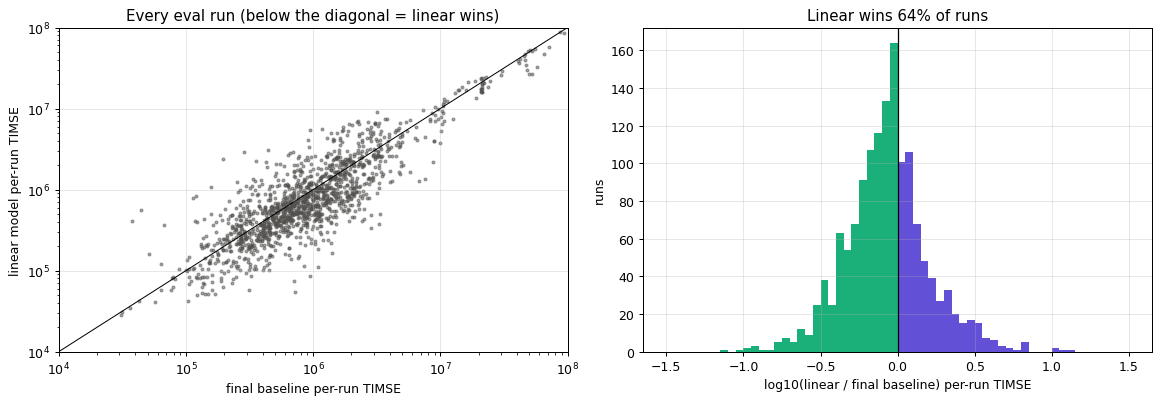

In [3]:
qs = [0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
quant = pd.DataFrame({m: run_scores[m].quantile(qs) for m in MODELS[:2]})
quant["linear / baseline"] = quant["linear_model"] / quant["final_baseline"]
quant.index = [f"p{int(q * 100)}" for q in qs]
display(fmt(quant))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
lo, hi = 1e4, 1e8
ax.plot([lo, hi], [lo, hi], color="k", lw=0.8)
ax.scatter(run_scores["final_baseline"], run_scores["linear_model"], s=5, alpha=0.5,
           color="#52514e")
ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi),
       xlabel="final baseline per-run TIMSE", ylabel="linear model per-run TIMSE",
       title="Every eval run (below the diagonal = linear wins)")
ax = axes[1]
r = np.log10(vs_base.dropna())
bins = np.linspace(-1.5, 1.5, 61)
ax.hist(r[r < 0], bins=bins, color=WIN)
ax.hist(r[r >= 0], bins=bins, color=LOSE)
ax.axvline(0, color="k", lw=1)
ax.set(xlabel="log10(linear / final baseline) per-run TIMSE", ylabel="runs",
       title=f"Linear wins {(r < 0).mean():.0%} of runs")
fig.tight_layout()

**Forecasts along the year.** The observed speed against the forecasts, from the first eval
run and then one run every 3 days. Runs are 72 h long, so each forecast starts where the
previous one ends: the forecasts tile the year without overlapping. Dotted lines mark each
run's `t0`, where the forecast restarts from the latest observation. One row per quarter.

In the first fit, some runs here were spiky bands: the forecast jumped at every sixth lead
(32, 38, … 68 h) after large flares. That was the training-data glitch of section 5.5.

With despiking, the bands are gone, but a smaller hour-to-hour jitter remains in some runs. It
comes from training on 6-hourly runs (section 5.5).

121 non-overlapping runs, 2025-10-20 00Z to 2026-10-18 00Z
per-run mean TIMSE on these runs: {'linear_model': '1.88e+06', 'final_baseline': '2.17e+06', 'persistence': '4.4e+06'} | linear wins 64%


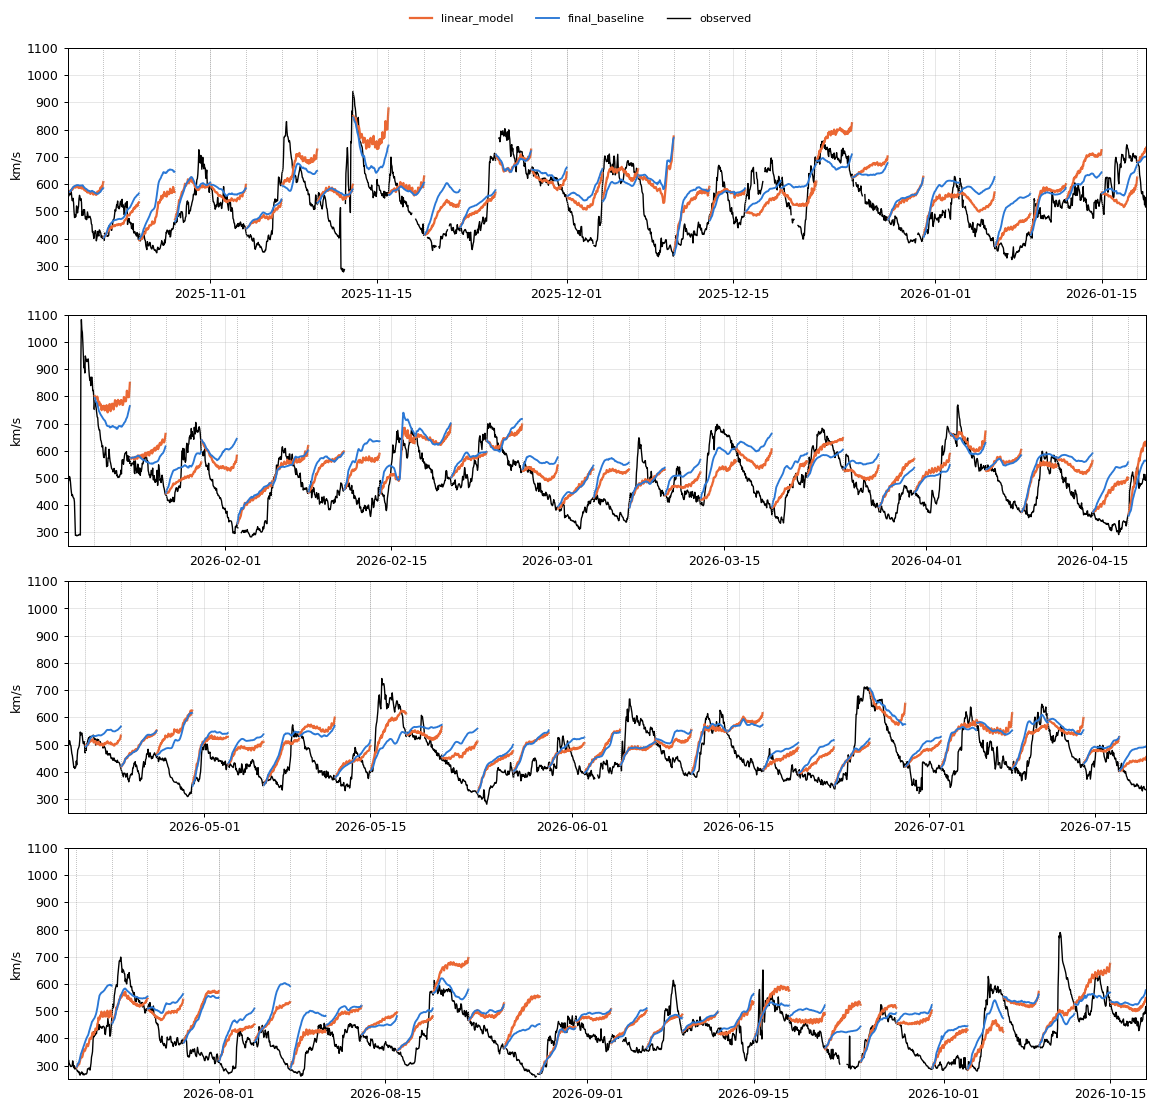

In [4]:
STRIDE = 72 // 6  # runs are 6-hourly; every 12th run is 3 days apart
tiled = np.arange(0, len(t0s), STRIDE)
tiled_times = [t0s[i] + pd.to_timedelta(lead, unit="h") for i in tiled]
valid_hours = tiled_times[0].append(tiled_times[1:])
# consecutive runs: no overlap and no gap
assert valid_hours.is_unique and (np.diff(valid_hours.asi8) == 3600 * 10**9).all()

tiled_scores = run_scores.iloc[tiled]
print(f"{len(tiled)} non-overlapping runs, {t0s[tiled[0]]:%Y-%m-%d %H}Z to "
      f"{t0s[tiled[-1]] + pd.Timedelta(hours=HORIZON):%Y-%m-%d %H}Z")
print("per-run mean TIMSE on these runs:",
      {m: f"{tiled_scores[m].mean():.3g}" for m in MODELS},
      f"| linear wins {(tiled_scores['linear_model'] < tiled_scores['final_baseline']).mean():.0%}")

quarters = pd.date_range(t0s[0], t0s[tiled[-1]] + pd.Timedelta(hours=HORIZON + 1), periods=5)
fig, axes = plt.subplots(4, 1, figsize=(13, 12))
for k, ax in enumerate(axes):
    lo, hi = quarters[k], quarters[k + 1]
    obs = series[lo:hi]
    ax.plot(obs.index, obs, color="k", lw=1.1)
    for r, i in enumerate(tiled):  # one line per run, so separate runs aren't joined
        if lo <= t0s[i] < hi:
            for m in MODELS[:2]:
                ax.plot(tiled_times[r], forecasts[m][i], **STYLE[m])
    for t in t0s[tiled][(t0s[tiled] >= lo) & (t0s[tiled] < hi)]:
        ax.axvline(t, color="0.6", lw=0.6, ls=":")
    ax.set(ylabel="km/s", xlim=(lo, hi), ylim=(250, 1100))
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=1.1), "observed")], models=MODELS[:2])

## 2. By regime

Each run is labelled by what happened during its 72 target hours (`ev.classify_runs`, as in
`final_baseline_analysis.ipynb`): CME, possible CME, stream arrival, fast stream, slow wind
(peak below 450 km/s), intermediate. The last four are the no-CME regimes.

For each regime:
- **runs** and their share of the year;
- **per-run mean** for both models, and the **change in the per-run total** it contributes (the regime's share of the overall change in the sum of per-run TIMSE: negative is a gain for the linear model);
- **median ratio** linear / baseline and how often the linear model wins;
- the median ratio of each model against persistence;
- **pooled TIMSE** of the linear model over the final baseline's, on the regime's runs.

In [5]:
cond_start = pd.Timestamp("2025-07-01T00:00Z")
minutes = ev.load_conditions(cond_start, EVAL_END)
hourly = minutes.resample("h").mean().reindex(
    pd.date_range(cond_start, EVAL_END, freq="h", inclusive="left", name="Time")
)
events = ev.detect_icmes(hourly, ev.detect_shocks(minutes))
cme = ev.cme_mask(hourly.index, events)
possible = ev.cme_mask(hourly.index, events, ("possible ICME",))
arrivals = ev.detect_stream_arrivals(hourly["speed"], cme | possible)
cme_hours = cme.reindex(series.index, fill_value=False)
possible_hours = possible.reindex(series.index, fill_value=False)
regime = pd.Series(ev.classify_runs(t0s, actual, cme_hours, arrivals, possible_hours),
                   index=t0s, name="regime")
no_cme = regime.isin(ev.NO_CME).to_numpy()

diff = run_scores["linear_model"] - run_scores["final_baseline"]
total_change = diff.sum()


def regime_row(sel):
    lin, base = run_scores.loc[sel, "linear_model"], run_scores.loc[sel, "final_baseline"]
    return {
        "runs": int(sel.sum()),
        "share of runs": sel.mean(),
        "linear mean": lin.mean(),
        "baseline mean": base.mean(),
        "share of total change": diff[sel].sum() / abs(total_change),
        "median linear / baseline": vs_base[sel].median(),
        "linear wins": (vs_base[sel] < 1).mean(),
        "median linear / persistence": vs_pers[sel].median(),
        "median baseline / persistence": base_vs_pers[sel].median(),
        "pooled linear / baseline": timse(actual[sel], forecasts["linear_model"][sel])
        / timse(actual[sel], forecasts["final_baseline"][sel]),
    }


rows = {r: regime_row((regime == r).to_numpy()) for r in ev.REGIMES}
rows["all no-CME"] = regime_row(no_cme)
rows["all"] = regime_row(np.ones(len(t0s), dtype=bool))
by_regime = pd.DataFrame(rows).T
by_regime["runs"] = by_regime["runs"].astype(int)
fmt(by_regime)

[solar_wind_events] plasma: 476/476 days


[solar_wind_events] mag: 476/476 days


,runs,share of runs,linear mean,baseline mean,share of total change,median linear / baseline,linear wins,median linear / persistence,median baseline / persistence,pooled linear / baseline
CME,295,0.204,6.87e+06,7.78e+06,-0.842,0.887,0.661,0.471,0.533,0.847
possible CME,81,0.0559,5.64e+05,6.88e+05,-0.0315,0.822,0.704,0.658,0.954,0.939
stream arrival,304,0.21,2.6e+06,2.17e+06,0.407,1.12,0.411,0.287,0.226,1.18
fast stream,105,0.0725,1.28e+06,1.45e+06,-0.0557,0.977,0.514,0.736,0.648,0.987
slow wind,186,0.128,6.43e+05,9.06e+05,-0.154,0.624,0.828,4.91,6.63,0.69
intermediate,477,0.329,6.65e+05,8.81e+05,-0.324,0.763,0.725,1.09,1.64,0.604
all no-CME,1072,0.74,1.27e+06,1.31e+06,-0.126,0.845,0.633,0.844,1.1,1.07
all,1448,1,2.37e+06,2.59e+06,-1,0.854,0.643,0.722,0.878,0.849


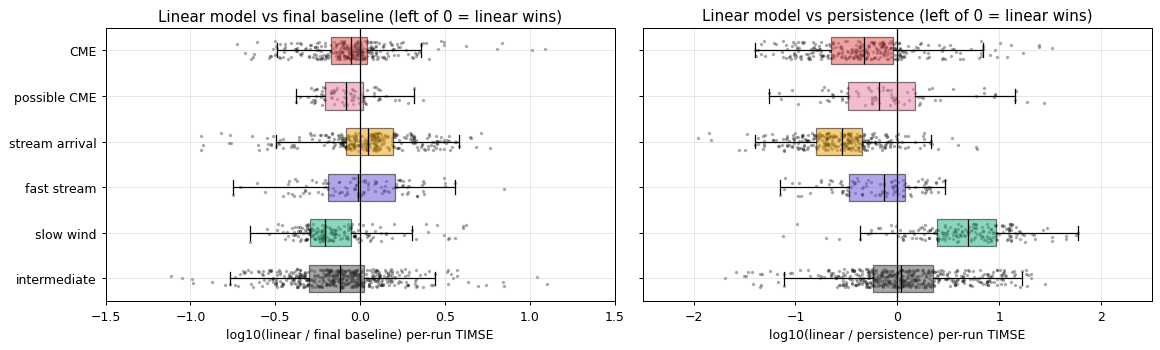

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
order = ev.REGIMES
for ax, (r, label) in zip(axes, [(vs_base, "final baseline"), (vs_pers, "persistence")],
                          strict=True):
    data = [np.log10(r[(regime == g).to_numpy()].dropna()) for g in order]
    parts = ax.boxplot(data, vert=False, showfliers=False, patch_artist=True,
                       widths=0.6, medianprops={"color": "k"})
    ax.set_yticks(range(1, len(order) + 1), order)
    for patch, g in zip(parts["boxes"], order, strict=True):
        patch.set(facecolor=REGIME_COLORS[g], alpha=0.5)
    rng = np.random.default_rng(0)
    for k, d in enumerate(data, 1):
        ax.scatter(d, k + rng.uniform(-0.2, 0.2, len(d)), s=3, color="k", alpha=0.25)
    ax.axvline(0, color="k", lw=1)
    ax.set(xlabel=f"log10(linear / {label}) per-run TIMSE",
           xlim=(-1.5, 1.5) if label == "final baseline" else (-2.5, 2.5),
           title=f"Linear model vs {label} (left of 0 = linear wins)")
axes[0].invert_yaxis()
fig.tight_layout()

## 3. Bias and level

The final baseline's main failure was a constant over-forecast of quiet wind: about 100 km/s too
high in slow and intermediate wind, growing with lead. Mean residual and RMSE by lead for each
regime (top: mean residual, negative = over-forecast; bottom: RMSE).

bias 6 h RMSE 6 h bias 24 h RMSE 24 h bias 72 h RMSE 72 h
CME            linear_model      -15.9     73.5     -47.9       120     -76.3       142
               final_baseline      -10       74     -42.8       122     -57.7       131
               persistence        2.19     75.5      15.3       134        45       172
possible CME   linear_model        -14     35.1     -52.2      77.4      -147       156
               final_baseline    -15.1     35.6     -62.7      84.6      -129       143
               persistence       -6.29     35.4     -23.5        83     -63.7       116
stream arrival linear_model      -7.68       43     -32.1      93.7    -0.709      86.7
               final_baseline    -9.44     46.1     -49.1       103     -14.3      80.7
               persistence        9.81       46      46.3       107       144       172
fast stream    linear_model       5.35     50.6      6.68      78.5      -151       171
               final_baseline     7.82     49.3      13.4      77.6      -133       158
               persistence        9.77     52.5      20.6       101     -97.7       152
slow wind      linear_model      -18.7     26.9     -76.6      86.2      -152       161
               final_baseline    -24.6     31.7     -97.8       108      -166       175
               persistence        -8.6     21.1     -24.3        44     -34.1      70.3
intermediate   linear_model      -13.6       33     -61.2      79.7      -154       169
               final_baseline    -17.5     35.1     -74.8      90.1      -159       174
               persistence       -6.18       32     -30.9        68     -73.4       126

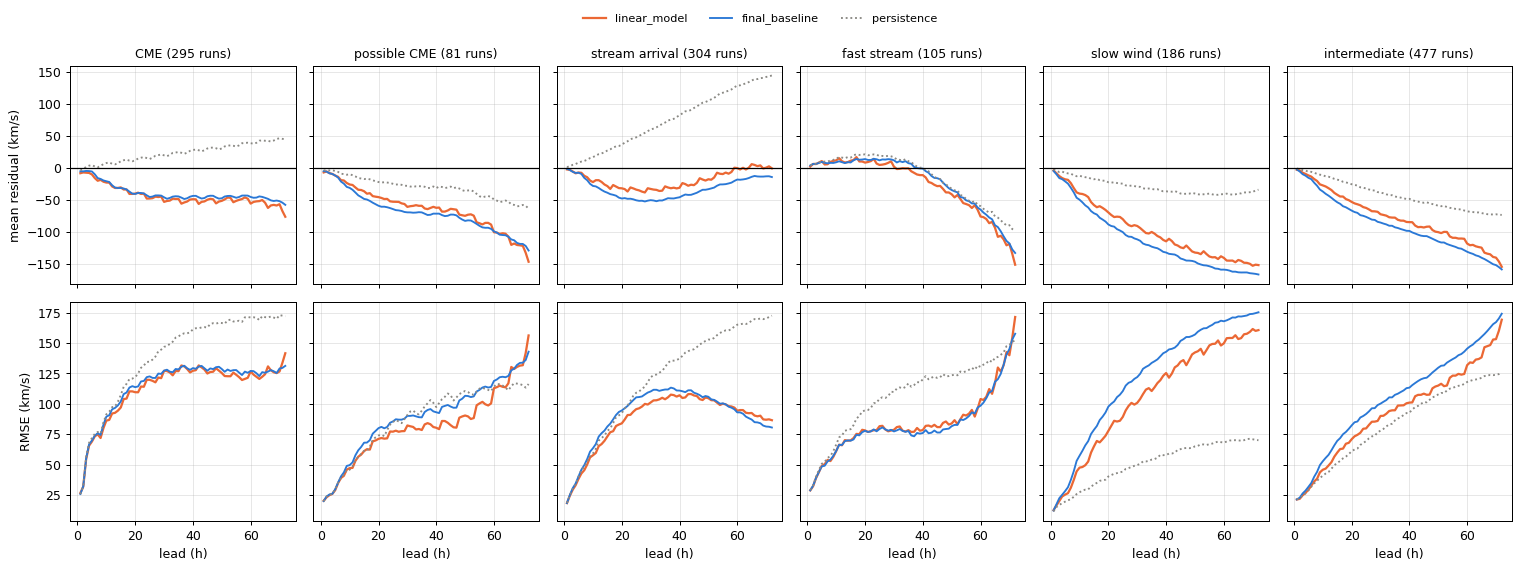

In [7]:
fig, axes = plt.subplots(2, len(ev.REGIMES), figsize=(17, 6), sharex=True, sharey="row")
bias_rows = {}
for col, g in enumerate(ev.REGIMES):
    sel = (regime == g).to_numpy()
    for m in MODELS:
        r = residuals[m][sel]
        axes[0, col].plot(lead, np.nanmean(r, axis=0), **STYLE[m])
        axes[1, col].plot(lead, np.sqrt(np.nanmean(r**2, axis=0)), **STYLE[m])
        for k in (6, 24, 72):
            bias_rows[(g, m)] = bias_rows.get((g, m), {}) | {
                f"bias {k} h": np.nanmean(r[:, k - 1]),
                f"RMSE {k} h": np.sqrt(np.nanmean(r[:, k - 1] ** 2)),
            }
    axes[0, col].axhline(0, color="k", lw=1)
    axes[0, col].set_title(f"{g} ({sel.sum()} runs)", fontsize=10)
    axes[1, col].set_xlabel("lead (h)")
axes[0, 0].set_ylabel("mean residual (km/s)")
axes[1, 0].set_ylabel("RMSE (km/s)")
fig.tight_layout()
model_legend(fig)
fmt(pd.DataFrame(bias_rows).T)

**Over-prediction in quiet wind, and the forecast floor.** For the no-CME regimes: the share of
each model's TIMSE that comes from over-prediction, and the median of (mean forecast − mean
observed) per run. Then the distribution of all forecasts at 24 h and 72 h lead against the
observed speeds (black): the final baseline almost never forecast below 450 km/s at 72 h.

share of TIMSE from over-prediction median (mean forecast - mean observed), km/s runs over-predicted on average
stream arrival linear_model                                 0.162                                         28.6                          0.678
               final_baseline                               0.273                                         39.5                          0.727
fast stream    linear_model                                 0.312                                         19.6                          0.705
               final_baseline                               0.246                                         21.5                          0.705
slow wind      linear_model                                 0.997                                           96                              1
               final_baseline                               0.998                                          104                              1
intermediate   linear_model                                 0.908                                         77.5                          0.981
               final_baseline                               0.918                                         86.7                          0.981

p1  p10 median  p90
24 h linear_model    370  424    505  626
     final_baseline  388  440    524  617
     observed        281  349    448  623
72 h linear_model    435  488    563  672
     final_baseline  447  502    567  655
     observed        281  349    448  623

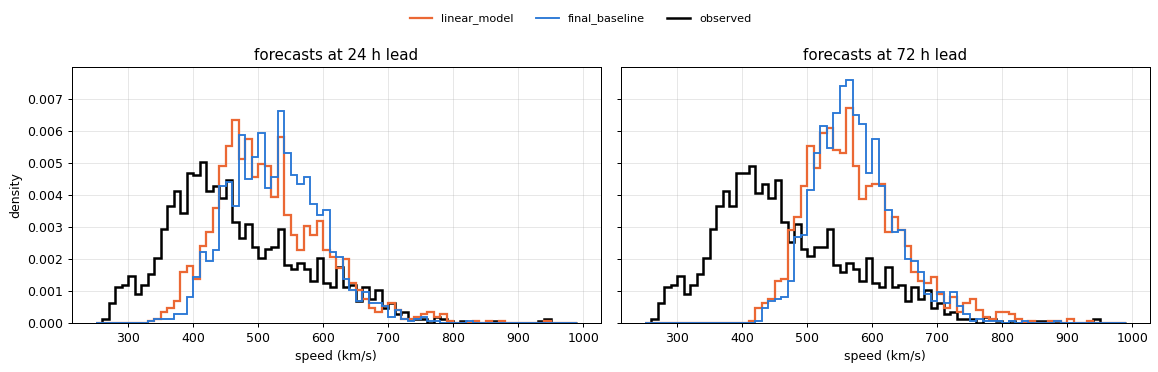

In [8]:
q = run_timse_weights(actual)
rows = {}
for g in ev.NO_CME:
    sel = (regime == g).to_numpy()
    for m in MODELS[:2]:
        e = residuals[m][sel]
        contrib = np.where(np.isfinite(e), q[sel] * e**2, 0.0)
        offset = np.nanmean(forecasts[m][sel], axis=1) - np.nanmean(actual[sel], axis=1)
        rows[(g, m)] = {
            "share of TIMSE from over-prediction": np.where(e < 0, contrib, 0).sum()
            / contrib.sum(),
            "median (mean forecast - mean observed), km/s": np.median(offset),
            "runs over-predicted on average": (offset > 0).mean(),
        }
display(fmt(pd.DataFrame(rows).T))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
bins = np.arange(250, 1000, 10)
quant = {}
for ax, k in zip(axes, (24, 72), strict=True):
    obs = actual[:, k - 1][np.isfinite(actual[:, k - 1])]
    ax.hist(obs, bins=bins, histtype="step", color="k", lw=2, density=True)
    for m in MODELS[:2]:
        ax.hist(forecasts[m][:, k - 1], bins=bins, histtype="step", density=True, **STYLE[m])
        quant[(f"{k} h", m)] = np.quantile(forecasts[m][:, k - 1], [0.01, 0.1, 0.5, 0.9])
    quant[(f"{k} h", "observed")] = np.quantile(obs, [0.01, 0.1, 0.5, 0.9])
    ax.set(title=f"forecasts at {k} h lead", xlabel="speed (km/s)")
axes[0].set_ylabel("density")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=2), "observed")], models=MODELS[:2])
fmt(pd.DataFrame(quant, index=["p1", "p10", "median", "p90"]).T)

## 4. Stream arrivals

The final baseline caught stream arrivals by already forecasting high, not by timing them. The
coronal-hole regressor is the one input that could give timing. A superposed-epoch view of the
non-CME stream arrivals: forecasts valid at each hour around the arrival (hour 0), made about 1, 2
or 3 days earlier, as the median over arrivals; black is the median observed speed.

The table gives the share of the observed rise each model reproduces: the mean over +12…+36 h
minus the mean over −36…−12 h, forecast over observed, median over arrivals.

29 non-CME stream arrivals


,linear_model: share of rise,final_baseline: share of rise,persistence: share of rise
~1 day ahead (19-30 h),0.387,0.27,0.42
~2 days ahead (43-54 h),0.127,0.0355,-0.156
~3 days ahead (61-72 h),0.0167,0.0236,-0.251


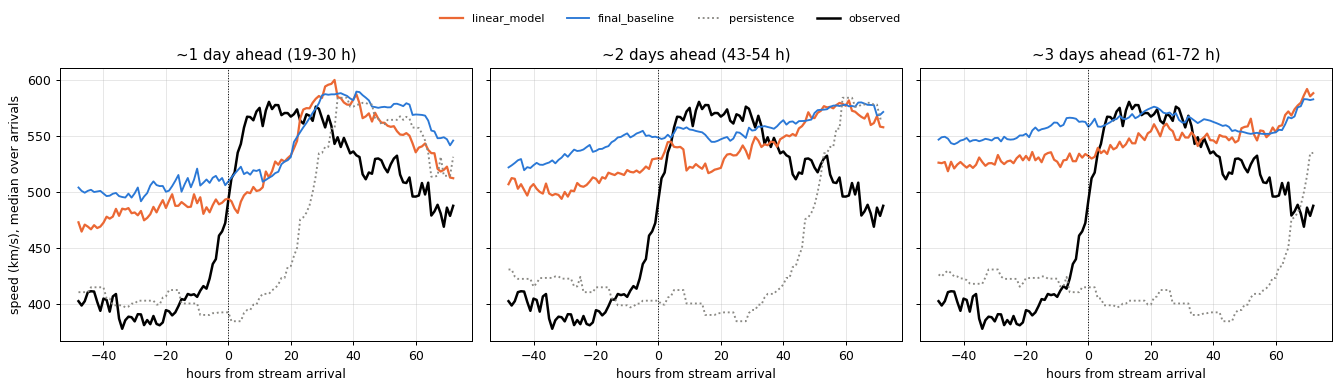

In [9]:
eval_arrivals = arrivals[(arrivals >= TRAIN_END + pd.Timedelta(days=3)) & (arrivals < EVAL_END)]
valid = t0s.values[:, None] + lead[None, :] * np.timedelta64(1, "h")
lead_grid = np.broadcast_to(lead, valid.shape)
groups = {"~1 day ahead (19-30 h)": (19, 30), "~2 days ahead (43-54 h)": (43, 54),
          "~3 days ahead (61-72 h)": (61, 72)}
rel_hours = np.arange(-48, 73)
epoch, capture = {}, {}
for gname, (lo, hi) in groups.items():
    stacks = {m: [] for m in MODELS}
    caps = {m: [] for m in MODELS}
    obs_stack = []
    for a in eval_arrivals:
        rel = (valid - a.tz_convert(None).to_datetime64()) / np.timedelta64(1, "h")
        sel = (rel >= -48) & (rel <= 72) & (lead_grid >= lo) & (lead_grid <= hi)
        obs = series.reindex(a + pd.to_timedelta(rel_hours, unit="h")).to_numpy()
        obs_stack.append(obs)
        rise_obs = np.nanmean(obs[(rel_hours >= 12) & (rel_hours <= 36)]) - np.nanmean(
            obs[(rel_hours >= -36) & (rel_hours <= -12)])
        for m in MODELS:
            df = pd.DataFrame({"rel": rel[sel].round().astype(int), "f": forecasts[m][sel]})
            curve = df.groupby("rel")["f"].mean().reindex(rel_hours)
            stacks[m].append(curve.to_numpy())
            after = curve[(curve.index >= 12) & (curve.index <= 36)].mean()
            before = curve[(curve.index >= -36) & (curve.index <= -12)].mean()
            caps[m].append((after - before) / rise_obs)
    epoch[gname] = ({m: np.nanmedian(np.array(stacks[m]), axis=0) for m in MODELS},
                    np.nanmedian(np.array(obs_stack), axis=0))
    capture[gname] = {m: np.nanmedian(caps[m]) for m in MODELS}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (gname, (curves, obs)) in zip(axes, epoch.items(), strict=True):
    ax.plot(rel_hours, obs, color="k", lw=2)
    for m in MODELS:
        ax.plot(rel_hours, curves[m], **STYLE[m])
    ax.axvline(0, color="k", lw=0.8, ls=":")
    ax.set(title=gname, xlabel="hours from stream arrival")
axes[0].set_ylabel("speed (km/s), median over arrivals")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=2), "observed")])
print(f"{len(eval_arrivals)} non-CME stream arrivals")
fmt(pd.DataFrame(capture).T.rename(columns=lambda m: f"{m}: share of rise"))

## 5. The regressors

### 5.1 Coefficients by lead

With no Box-Cox transform and the target relative to persistence, every term is in km/s: the
model forecasts `last + a_k + Σ b_kj·(speed term − mean) + Σ c_ki·z_i` plus a small smearing
constant. Left: the speed-term coefficients (km/s per km/s). Right: the regressor coefficients,
in km/s per standard deviation of the regressor (`z_i` is standardised on the training years).
The coefficients of the submodel (no coronal-hole regressor) are dashed.

,1,6,24,48,72
last speed,-0.017,-0.101,-0.441,-0.603,-0.455
recurrence 27 d,0.03,0.0668,0.235,0.224,0.154
recurrence 13.5 d,-0.00236,-0.0111,0.00735,-0.00614,0.0249
ch_cm_at_12h,-0.311,3.78,14.3,28.4,24.2
density_mean_24h,1.99,9.88,18.5,13.5,11.9
xray_peak_max_48h,0.869,5.59,14.1,11.6,12.9
b_var_mean_48h,-2.17,-1.88,-0.021,-5.38,-6.83


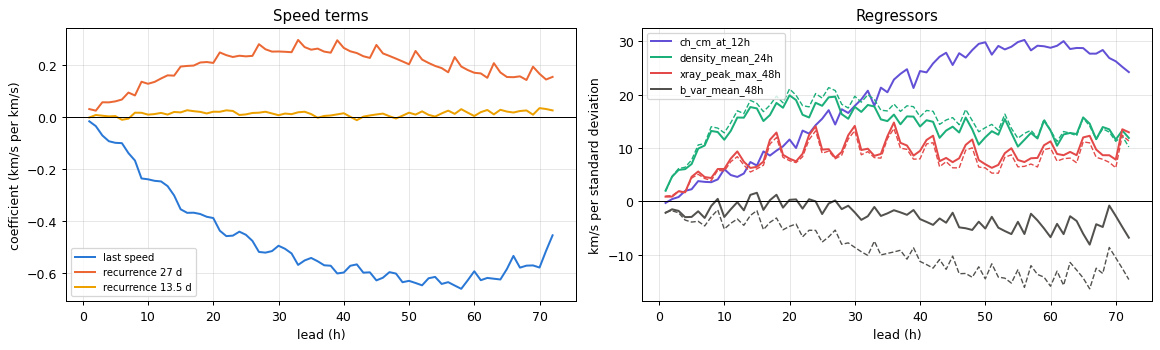

In [10]:
cfg = model.config
speed_names = ["last speed"] + [f"recurrence {d:g} d" for d in cfg.lags_days]
coef = pd.DataFrame(model.coef[:, 1:], index=lead, columns=speed_names + FEATURES)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, color in zip(speed_names, ["#2a78d6", "#eb6834", "#eda100"], strict=True):
    axes[0].plot(lead, coef[name], color=color, lw=1.6, label=name)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set(xlabel="lead (h)", ylabel="coefficient (km/s per km/s)", title="Speed terms")
axes[0].legend(fontsize=8)
palette = ["#6250d6", "#1baf7a", "#e34948", "#52514e", "#e87ba4", "#eda100"]
feat_colors = dict(zip(FEATURES, palette, strict=False))
sub_model = model.fallback
sub_cols = 1 + sub_model.config.n_speed
for name in FEATURES:
    axes[1].plot(lead, coef[name], color=feat_colors[name], lw=1.6, label=name)
    if name in sub_model.config.features:
        j = sub_cols + sub_model.config.features.index(name)
        axes[1].plot(lead, sub_model.coef[:, j], color=feat_colors[name], lw=1.1, ls="--")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(xlabel="lead (h)", ylabel="km/s per standard deviation", title="Regressors")
axes[1].legend(fontsize=8)
fig.tight_layout()
fmt(coef.loc[[1, 6, 24, 48, 72]].T)

### 5.2 Contributions by regime

Each regressor's contribution to a forecast is `c_ki · z_i` in km/s. The table gives its mean
contribution at 24 h and 72 h lead by regime, and the spread (standard deviation over runs). Only
runs forecast by the main model are included (not the submodel runs without a coronal-hole image).
If a regressor separates the regimes, its contribution should be negative in slow wind (pulling
the forecast down) and positive before stream arrivals.

In [11]:
main_runs = ~submodel.to_numpy()
z = (model.impute(x) - model.x_mean) / model.x_std
n_lead_cols = 1 + cfg.n_speed
contrib = {name: z[:, [j]] * model.coef[None, :, n_lead_cols + j]
           for j, name in enumerate(FEATURES)}
contrib["all regressors"] = sum(contrib.values())
rows = {}
for name, c in contrib.items():
    for k in (24, 72):
        row = {g: c[(regime == g).to_numpy() & main_runs, k - 1].mean() for g in ev.REGIMES}
        row["std over runs"] = c[main_runs, k - 1].std()
        rows[(name, f"{k} h")] = row
fmt(pd.DataFrame(rows).T)

CME possible CME stream arrival fast stream  slow wind intermediate std over runs
ch_cm_at_12h      24 h      12.7         2.88           11.4        24.6       1.22         4.54          19.3
                  72 h      21.6         4.88           19.3        41.7       2.08         7.71          32.7
density_mean_24h  24 h     -2.35          -11           -6.2       -1.68      -8.98        -7.02          13.2
                  72 h     -1.51        -7.05          -3.99       -1.08      -5.77        -4.52          8.48
xray_peak_max_48h 24 h      1.18        0.794          -5.09       -4.02      -7.95        -5.92          13.7
                  72 h      1.09        0.731          -4.69        -3.7      -7.31        -5.44          12.6
b_var_mean_48h    24 h  0.000865      0.00649        0.00299    -0.00628  -0.000601     -0.00888        0.0228
                  72 h     0.282         2.11          0.974       -2.04     -0.196        -2.89          7.43
all regressors    24 h      11.5        -7.28         0.0655        18.9      -15.7        -8.41          28.4
                  72 h      21.4        0.679           11.6        34.9      -11.2        -5.14            40

### 5.3 Ablation

How much each regressor is worth on the eval year: the same fitted model, with one regressor
replaced by its training median for every run (the value an imputed run gets). The change is in
per-run mean and median TIMSE relative to the full model; positive means the regressor helps.
- **"All regressors"** replaces all four with their medians, leaving the speed terms of the main model.
- **"submodel for every run"** marks the coronal-hole image missing everywhere, so every run goes to the submodel: what the gap costs.

These are analyses of the fitted models, not refits.

In [12]:
def scores(f):
    s = run_timse(f, actual)
    return np.nanmean(s), np.nanmedian(s), timse(actual, f)


full = scores(forecasts["linear_model"])
rows = {}
for j, name in enumerate([*FEATURES, "all regressors", "submodel for every run"]):
    xa = x.copy()
    if name == "all regressors":
        xa[:] = model.medians
    elif name == "submodel for every run":
        xa[:, [FEATURES.index(f) for f in cfg.optional]] = np.nan
    else:
        xa[:, j] = model.medians[j]
    s = scores(model.forecast(values, pos, xa))
    rows[name] = {"per-run mean, worse by": s[0] / full[0] - 1,
                  "per-run median, worse by": s[1] / full[1] - 1,
                  "pooled TIMSE, worse by": s[2] / full[2] - 1,
                  "per-run mean vs baseline": s[0] / run_scores["final_baseline"].mean()}
fmt(pd.DataFrame(rows).T)

,"per-run mean, worse by","per-run median, worse by","pooled TIMSE, worse by",per-run mean vs baseline
ch_cm_at_12h,0.19,-0.218,0.337,1.09
density_mean_24h,0.0237,0.0464,-0.0196,0.937
xray_peak_max_48h,0.0409,0.0623,0.0501,0.953
b_var_mean_48h,0.00232,0.0199,-0.00263,0.917
all regressors,0.261,-0.111,0.365,1.15
submodel for every run,0.0702,-0.0523,0.21,0.979


### 5.4 The coronal-hole gap

The SDO browse archive has no AIA 193 images for about 2025-09-12 → 2025-12-16, and for 9 days in
March 2026. The fallback to the 18 h or 24 h image covers only short outages, so these runs go to
the submodel without the coronal-hole regressor. In the first fit they were imputed with the
median strip instead, and the model only tied the baseline on them (median ratio 0.99, 51% of runs
won).

Top: the regressor over the year, with the submodel runs shaded. The table compares the linear
model against the final baseline on the submodel runs, and on the observed runs split by quartile
of coronal-hole area.

,runs,area range,linear mean,baseline mean,median linear / baseline,linear wins,"mean residual 72 h, linear","mean residual 72 h, baseline"
submodel,279,-,4.4e+06,4.48e+06,0.879,0.606,-94.1,-99.9
observed Q1 (small),293,0.000-0.011,8.54e+05,1.04e+06,0.613,0.836,-118,-143
observed Q2,292,0.011-0.038,1.1e+06,1.28e+06,0.743,0.74,-100,-113
observed Q3,292,0.038-0.099,1.54e+06,1.61e+06,0.933,0.582,-98.4,-97.9
observed Q4 (large),292,0.100-0.366,4.06e+06,4.65e+06,1.1,0.449,-114,-70.6


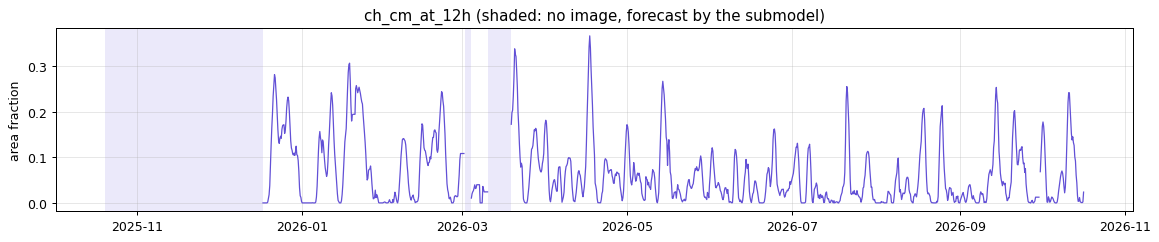

In [13]:
ch = table["ch_cm_at_12h"]
ch_missing = submodel
fig, ax = plt.subplots(figsize=(13, 2.8))
ax.plot(ch.index, ch, color="#6250d6", lw=1)
for s, e in ev._runs(ch_missing.to_numpy()):
    ax.axvspan(t0s[s], t0s[e - 1] + pd.Timedelta(hours=6), **GAP_SPAN)
ax.set(ylabel="area fraction",
       title="ch_cm_at_12h (shaded: no image, forecast by the submodel)")
fig.tight_layout()

groups_ch = pd.Series(np.where(ch_missing, "submodel", ""), index=t0s, dtype=object)
groups_ch[~ch_missing] = pd.qcut(ch[~ch_missing], 4,
                                 labels=["observed Q1 (small)", "observed Q2", "observed Q3",
                                         "observed Q4 (large)"]).astype(str)
rows = {}
for g in ["submodel", "observed Q1 (small)", "observed Q2", "observed Q3", "observed Q4 (large)"]:
    sel = (groups_ch == g).to_numpy()
    rows[g] = {"runs": int(sel.sum()),
               "area range": f"{ch[sel].min():.3f}-{ch[sel].max():.3f}" if g != "submodel"
               else "-",
               "linear mean": run_scores.loc[sel, "linear_model"].mean(),
               "baseline mean": run_scores.loc[sel, "final_baseline"].mean(),
               "median linear / baseline": vs_base[sel].median(),
               "linear wins": (vs_base[sel] < 1).mean(),
               "mean residual 72 h, linear": np.nanmean(residuals["linear_model"][sel, 71]),
               "mean residual 72 h, baseline": np.nanmean(residuals["final_baseline"][sel, 71])}
fmt(pd.DataFrame(rows).T)

### 5.5 Despiking: the glitch before and after

The first fit's coefficients, forecasts and residuals jumped at every sixth lead (8, 14, 20, … h).
The cause was in the **training** data:
- **The glitch:** a one-hour glitch in the real-time series, 1,087 km/s at 2022-10-05 02:00 between hours of about 500 km/s.
- **Why every sixth lead:** runs start every 6 hours, so the glitch hour was the target of training runs at leads 2, 8, 14, … h.
- **Why it mattered:** TIMSE weights favour a run's fastest hours, so this single hour took up to 2% of the fitting weight at each of those leads, more than any other run-hour.

The shipped model drops such isolated one-hour glitches before fitting (`recurrence.despike`).
The table lists the hours dropped in the training years. The figure shows:
- **left:** the glitch;
- **middle:** the largest weight any single run-hour gets at each lead, on the raw targets (grey; purple where it is the glitch) and on the despiked targets (black);
- **right:** one coefficient of the shipped fit, against the same config refitted without despiking.

The refit is a training-side diagnostic, not scored here.

**What despiking doesn't remove.** A smaller six-lead pattern remains, visible in the flare
coefficient in 5.1 and in the middle panel's black line. It comes from the training design, not
from glitches:
- **The run grid:** runs start every 6 hours, so lead k only ever sees target hours at one time of day modulo 6 (lead 1 sees hours 1, 7, 13 and 19 UTC; lead 2 sees 2, 8, 14 and 20; and so on).
- **The effect:** leads in different classes are fitted on disjoint sets of hours, and any high-weight fast hour pulls one class only.
- **Fixes:** train on hourly forecast times (6× more runs, every lead sees every hour), or tie neighbouring leads together.

,speed (km/s),median of the 3 h before,median of the 3 h after
Time,,,
2022-01-08 01:00,634.0,299.0,297.0
2022-10-05 02:00,1087.0,497.0,503.0
2023-08-06 11:00,521.0,370.0,350.0
2023-11-24 22:00,598.0,391.0,446.0


raw targets: the glitch carries the largest single weight at 11 leads; largest share 2.1% -> 0.8% after despiking


,without despiking,shipped (despiked)
mean |second difference| over leads,,
last speed,0.0937,0.0244
recurrence 27 d,0.052,0.0278
recurrence 13.5 d,0.044,0.0119
ch_cm_at_12h,5.46,1.94
density_mean_24h,5.22,2.51
xray_peak_max_48h,11.7,2.42
b_var_mean_48h,11.8,2.47


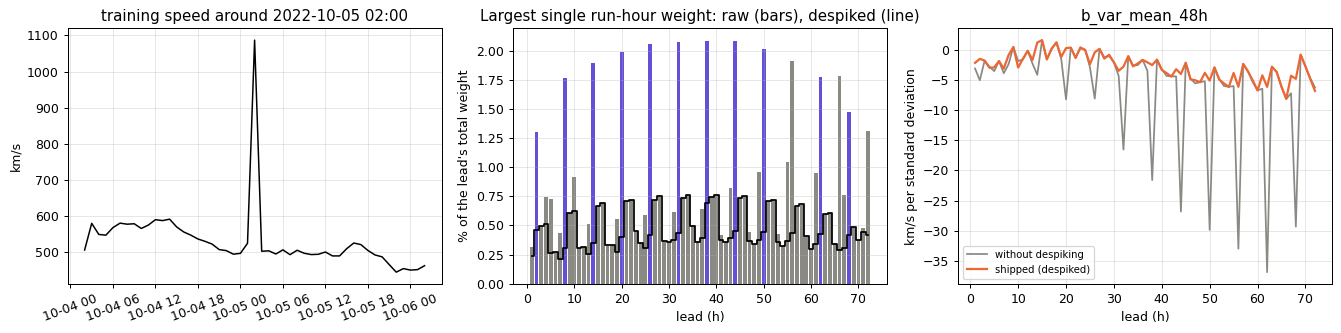

In [14]:
from dataclasses import replace

from feature_engineering.recurrence import despike
from training.datasets import load_train
from training.linear_model import training_runs

train = load_train()
tv = train.to_numpy(dtype=float)
clean = despike(tv)
dropped = np.isnan(clean) & np.isfinite(tv)
k = np.flatnonzero(dropped)
display(pd.DataFrame({"speed (km/s)": tv[k],
                      "median of the 3 h before": [np.nanmedian(tv[i - 3:i]) for i in k],
                      "median of the 3 h after": [np.nanmedian(tv[i + 1:i + 4]) for i in k]},
                     index=train.index[k].strftime("%Y-%m-%d %H:%M")).round(0))

train_t0s = training_runs(train)
tpos = train.index.get_indexer(train_t0s)


def max_share(series):
    w = model.loss_weights(targets(series, tpos))
    w = w / w.sum(axis=0)
    return w.max(axis=0), train_t0s[w.argmax(axis=0)] + pd.to_timedelta(lead, unit="h")


raw_share, raw_top = max_share(tv)
clean_share, _ = max_share(clean)
glitch = pd.Timestamp("2022-10-05T02:00Z")
is_glitch = raw_top == glitch
print(f"raw targets: the glitch carries the largest single weight at {is_glitch.sum()} leads; "
      f"largest share {raw_share.max():.1%} -> {clean_share.max():.1%} after despiking")

train_x = candidate_table(train_t0s)[FEATURES].to_numpy(dtype=float)
raw_fit = LinearModel(replace(model.config, despike=False)).fit(tv, tpos, train_x)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
w = train[glitch - pd.Timedelta(hours=24): glitch + pd.Timedelta(hours=24)]
axes[0].plot(w.index, w, color="k", lw=1.2)
axes[0].set(ylabel="km/s", title="training speed around 2022-10-05 02:00")
axes[0].tick_params(axis="x", labelrotation=20)
axes[1].bar(lead, raw_share * 100, color=np.where(is_glitch, LOSE, "#8a8984"))
axes[1].plot(lead, clean_share * 100, color="k", lw=1.4, drawstyle="steps-mid")
axes[1].set(xlabel="lead (h)", ylabel="% of the lead's total weight",
            title="Largest single run-hour weight: raw (bars), despiked (line)")
name = "b_var_mean_48h"
j = 1 + cfg.n_speed + FEATURES.index(name)
axes[2].plot(lead, raw_fit.coef[:, j], color="#8a8984", lw=1.4, label="without despiking")
axes[2].plot(lead, model.coef[:, j], **STYLE["linear_model"], label="shipped (despiked)")
axes[2].set(xlabel="lead (h)", ylabel="km/s per standard deviation", title=name)
axes[2].legend(fontsize=8)
fig.tight_layout()


def roughness(c):
    return np.abs(np.diff(c, 2, axis=0)).mean(axis=0)


fmt(pd.DataFrame({"without despiking": roughness(raw_fit.coef[:, 1:]),
                  "shipped (despiked)": roughness(model.coef[:, 1:])},
                 index=speed_names + FEATURES).rename_axis(
                     "mean |second difference| over leads"))

## 6. Through the year

### 6.1 Month by month

Per-run mean TIMSE by month for both models, the linear model's win share, the share of runs
forecast by the submodel (no coronal-hole image), and each month's share of the year's change in the
per-run total (negative = a gain for the linear model; the column sums to −1).

,runs,linear mean,baseline mean,persistence mean,linear wins,submodel runs,CME runs,linear / baseline (means),share of total change
2025-10,48,1.28e+06,1.71e+06,3.46e+06,0.583,1,0,0.748,-0.065
2025-11,120,8.06e+06,8.16e+06,1.45e+07,0.625,1,0.4,0.988,-0.0384
2025-12,124,1.72e+06,1.53e+06,4.65e+06,0.46,0.532,0.242,1.12,0.0714
2026-01,124,7.42e+06,8.6e+06,1.38e+07,0.54,0,0.25,0.862,-0.462
2026-02,112,1.11e+06,1.47e+06,3.6e+06,0.768,0,0.277,0.756,-0.126
2026-03,124,1.37e+06,1.33e+06,3.9e+06,0.613,0.355,0.355,1.03,0.0131
2026-04,120,1.27e+06,1.35e+06,3e+06,0.642,0,0.125,0.939,-0.031
2026-05,124,9.1e+05,1.29e+06,3.05e+06,0.694,0,0.129,0.708,-0.146
2026-06,120,1.31e+06,1.54e+06,4.19e+06,0.792,0,0.383,0.85,-0.0872
2026-07,124,7.89e+05,9.89e+05,3.79e+06,0.742,0,0.0645,0.798,-0.0778


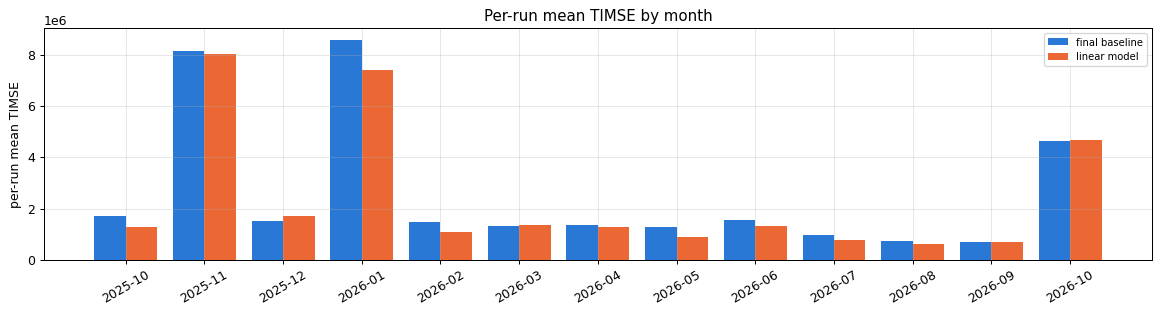

In [15]:
month = pd.Series(t0s.strftime("%Y-%m"), index=t0s)
monthly = pd.DataFrame({
    "runs": month.value_counts().sort_index(),
    "linear mean": run_scores["linear_model"].groupby(month).mean(),
    "baseline mean": run_scores["final_baseline"].groupby(month).mean(),
    "persistence mean": run_scores["persistence"].groupby(month).mean(),
    "linear wins": (vs_base < 1).groupby(month).mean(),
    "submodel runs": ch_missing.groupby(month).mean(),
    "CME runs": (regime == "CME").groupby(month).mean(),
})
monthly["linear / baseline (means)"] = monthly["linear mean"] / monthly["baseline mean"]
monthly["share of total change"] = diff.groupby(month).sum() / abs(total_change)

fig, ax = plt.subplots(figsize=(13, 3.6))
xm = np.arange(len(monthly))
ax.bar(xm - 0.2, monthly["baseline mean"], 0.4, color=STYLE["final_baseline"]["color"],
       label="final baseline")
ax.bar(xm + 0.2, monthly["linear mean"], 0.4, color=STYLE["linear_model"]["color"],
       label="linear model")
ax.set_xticks(xm, monthly.index, rotation=30)
ax.set(ylabel="per-run mean TIMSE", title="Per-run mean TIMSE by month")
ax.legend(fontsize=8)
fig.tight_layout()
fmt(monthly)

### 6.2 The year, run by run

Each pair of rows shows the observed speed (CME-affected time shaded red, possible CMEs pink,
coronal-hole regressor missing shaded purple), then the per-run ratio linear / final baseline on a
log scale at each run's `t0`: green below 1 (the linear model wins), purple above.

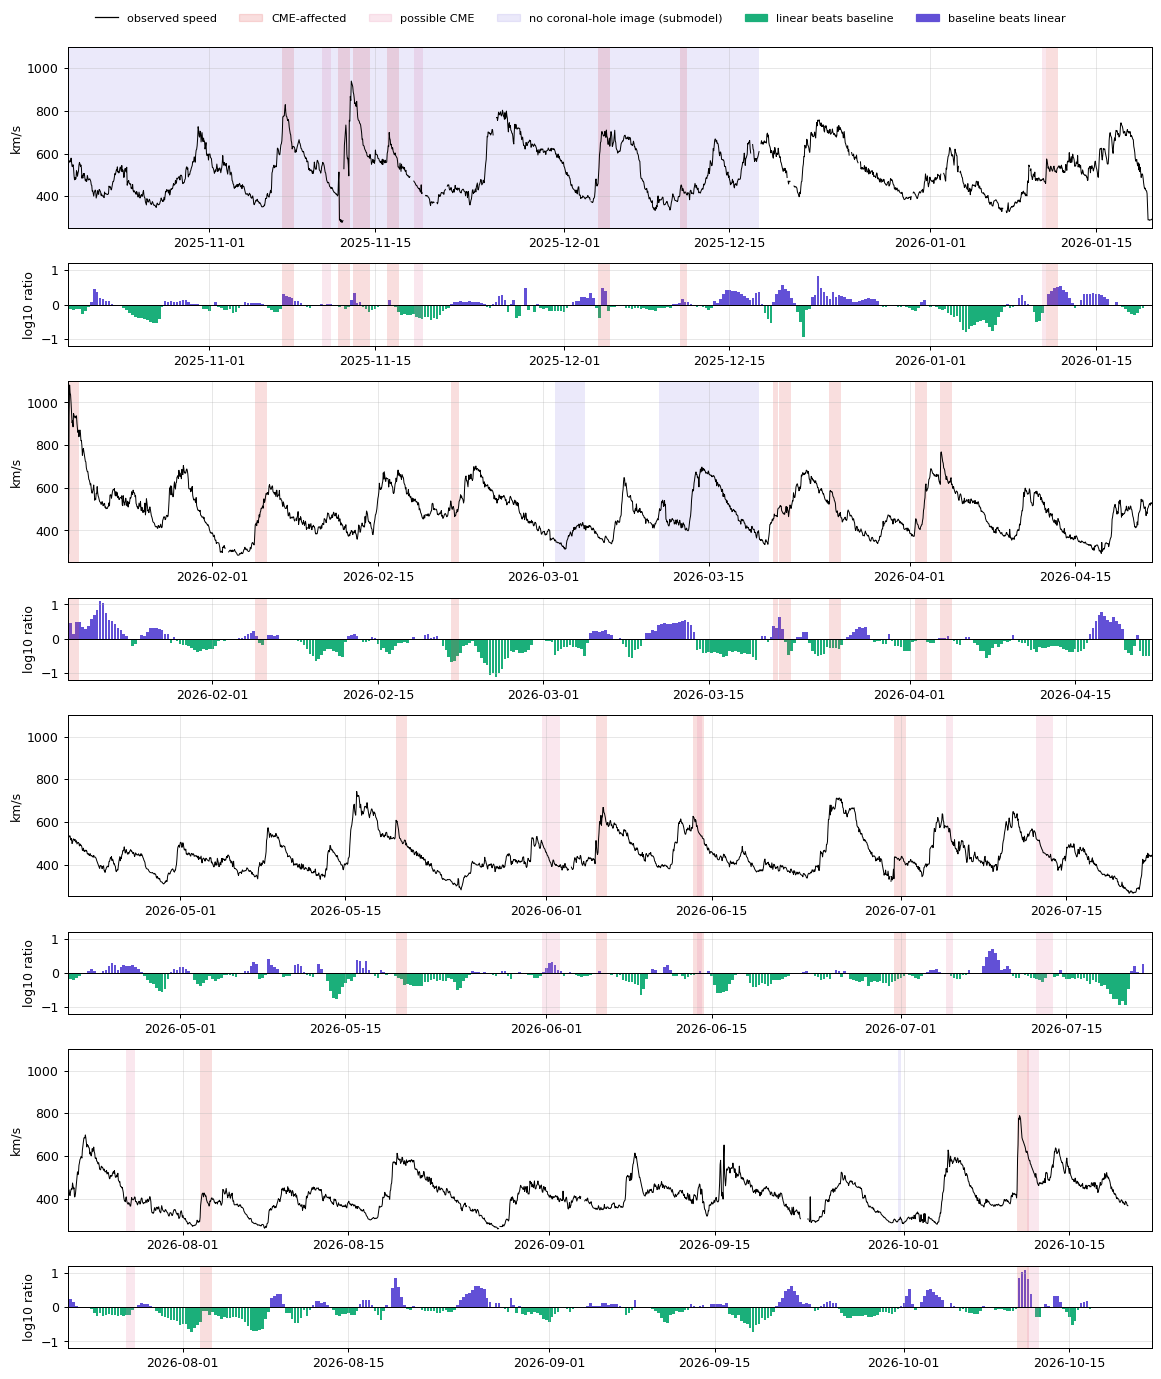

In [16]:
def shade(ax, lo, hi, gap=True):
    for mask, span in ((cme, CME_SPAN), (possible, POSSIBLE_SPAN)):
        m = mask[(mask.index >= lo) & (mask.index < hi)]
        for s, e in ev._runs(m.to_numpy()):
            ax.axvspan(m.index[s], m.index[e - 1] + pd.Timedelta(hours=1), **span)
    if gap:
        m = ch_missing[(ch_missing.index >= lo) & (ch_missing.index < hi)]
        for s, e in ev._runs(m.to_numpy()):
            ax.axvspan(m.index[s], m.index[e - 1] + pd.Timedelta(hours=6), **GAP_SPAN)


quarters = pd.date_range(TRAIN_END, EVAL_END + pd.Timedelta(days=2), periods=5)
fig, axes = plt.subplots(8, 1, figsize=(13, 15), gridspec_kw={"height_ratios": [2.2, 1] * 4})
log_ratio = np.log10(vs_base)
for k in range(4):
    lo, hi = quarters[k], quarters[k + 1]
    ax_v, ax_r = axes[2 * k], axes[2 * k + 1]
    s = series[lo:hi]
    ax_v.plot(s.index, s, color="k", lw=0.8)
    shade(ax_v, lo, hi)
    ax_v.set(ylabel="km/s", xlim=(lo, hi), ylim=(250, 1100))
    r = log_ratio[(log_ratio.index >= lo) & (log_ratio.index < hi)]
    ax_r.bar(r.index, r, width=0.22, color=np.where(r < 0, WIN, LOSE))
    ax_r.axhline(0, color="k", lw=0.8)
    shade(ax_r, lo, hi, gap=False)
    ax_r.set(ylabel="log10 ratio", xlim=(lo, hi), ylim=(-1.2, 1.2))
fig.tight_layout()
fig.legend(
    [Line2D([], [], color="k", lw=1), Patch(**{k: v for k, v in CME_SPAN.items() if k != "lw"}),
     Patch(**{k: v for k, v in POSSIBLE_SPAN.items() if k != "lw"}),
     Patch(**{k: v for k, v in GAP_SPAN.items() if k != "lw"}),
     Patch(color=WIN), Patch(color=LOSE)],
    ["observed speed", "CME-affected", "possible CME", "no coronal-hole image (submodel)",
     "linear beats baseline", "baseline beats linear"],
    loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=6, frameon=False, fontsize=9,
);

### 6.3 The worst runs

The ten runs with the highest linear-model TIMSE (they set the per-run mean and the p90), and
the ten where it loses most heavily to the final baseline.

In [17]:
cols = pd.DataFrame({
    "regime": regime,
    "linear": run_scores["linear_model"],
    "baseline": run_scores["final_baseline"],
    "persistence": run_scores["persistence"],
    "linear / baseline": vs_base,
    "peak observed": np.nanmax(actual, axis=1),
    "last speed": forecasts["persistence"][:, 0],
    "submodel": ch_missing,
    **{f: table[f] for f in FEATURES[:2]},
})
shown = cols.copy()
shown.index = shown.index.strftime("%Y-%m-%d %H")
print("Highest per-run TIMSE (linear model):")
display(fmt(shown.sort_values("linear", ascending=False).head(10)))
print("Largest losses to the final baseline (runs with baseline TIMSE above the median):")
big = shown[shown["baseline"] > shown["baseline"].median()]
display(fmt(big.sort_values("linear / baseline", ascending=False).head(10)))

Highest per-run TIMSE (linear model):


,regime,linear,baseline,persistence,linear / baseline,peak observed,last speed,submodel,ch_cm_at_12h,density_mean_24h
2026-01-19 18,CME,1.73e+08,1.89e+08,2.77e+08,0.916,1.08e+03,292,False,0.194,1.33
2026-01-19 12,CME,1.46e+08,1.56e+08,2.84e+08,0.934,1.08e+03,289,False,0.193,0.787
2025-11-12 06,CME,8.73e+07,8.77e+07,1.69e+08,0.995,940,277,True,nan,3.36
2026-01-19 06,CME,8.52e+07,9.3e+07,1.72e+08,0.917,1.08e+03,431,False,0.179,0.668
2026-01-19 00,CME,5.77e+07,7.17e+07,1.28e+08,0.806,1.08e+03,501,False,0.213,0.707
2025-11-11 18,CME,5.49e+07,5.58e+07,9.86e+07,0.984,940,410,True,nan,2.81
2025-11-11 06,CME,5.23e+07,5.05e+07,8.47e+07,1.04,940,444,True,nan,4.55
2025-11-11 00,CME,5.19e+07,4.88e+07,7.57e+07,1.06,940,469,True,nan,4.95
2025-11-11 12,CME,5.06e+07,5.26e+07,9.12e+07,0.962,940,427,True,nan,4.13
2026-01-18 18,CME,4.77e+07,6.58e+07,1.21e+08,0.725,1.08e+03,516,False,0.268,0.89


Largest losses to the final baseline (runs with baseline TIMSE above the median):


,regime,linear,baseline,persistence,linear / baseline,peak observed,last speed,submodel,ch_cm_at_12h,density_mean_24h
2026-04-17 06,stream arrival,5.49e+06,9.39e+05,9.82e+06,5.84,542,292,False,0.366,3.12
2026-04-17 00,stream arrival,5.62e+06,1.17e+06,7.7e+06,4.8,542,320,False,0.341,3.06
2026-04-17 12,stream arrival,4.12e+06,9.13e+05,7.43e+06,4.51,542,312,False,0.339,3.22
2025-12-19 12,stream arrival,5.01e+06,1.38e+06,8.38e+06,3.64,757,534,False,0.00971,1.41
2026-04-17 18,stream arrival,3.35e+06,9.28e+05,6.15e+06,3.61,546,337,False,0.291,3.88
2026-03-13 00,stream arrival,5.94e+06,1.71e+06,1.64e+07,3.47,697,420,True,nan,0.697
2026-10-03 06,stream arrival,6.5e+06,1.92e+06,2.33e+07,3.38,628,307,False,0.00196,2.3
2026-04-16 18,stream arrival,4.28e+06,1.28e+06,7.42e+06,3.35,542,324,False,0.287,3.18
2026-03-12 18,stream arrival,5e+06,1.53e+06,1.52e+07,3.26,697,432,True,nan,0.666
2026-01-20 18,fast stream,5.43e+06,1.71e+06,6.08e+06,3.17,871,839,False,0.25,3.54


Four examples:
- the linear model's worst run by TIMSE;
- its heaviest loss to the final baseline among stream arrivals;
- its biggest win over the final baseline in slow wind;
- its biggest win among intermediate runs.

Each panel shows the 48 h before `t0`, then the 72 h forecasts, with the observed speed in black.

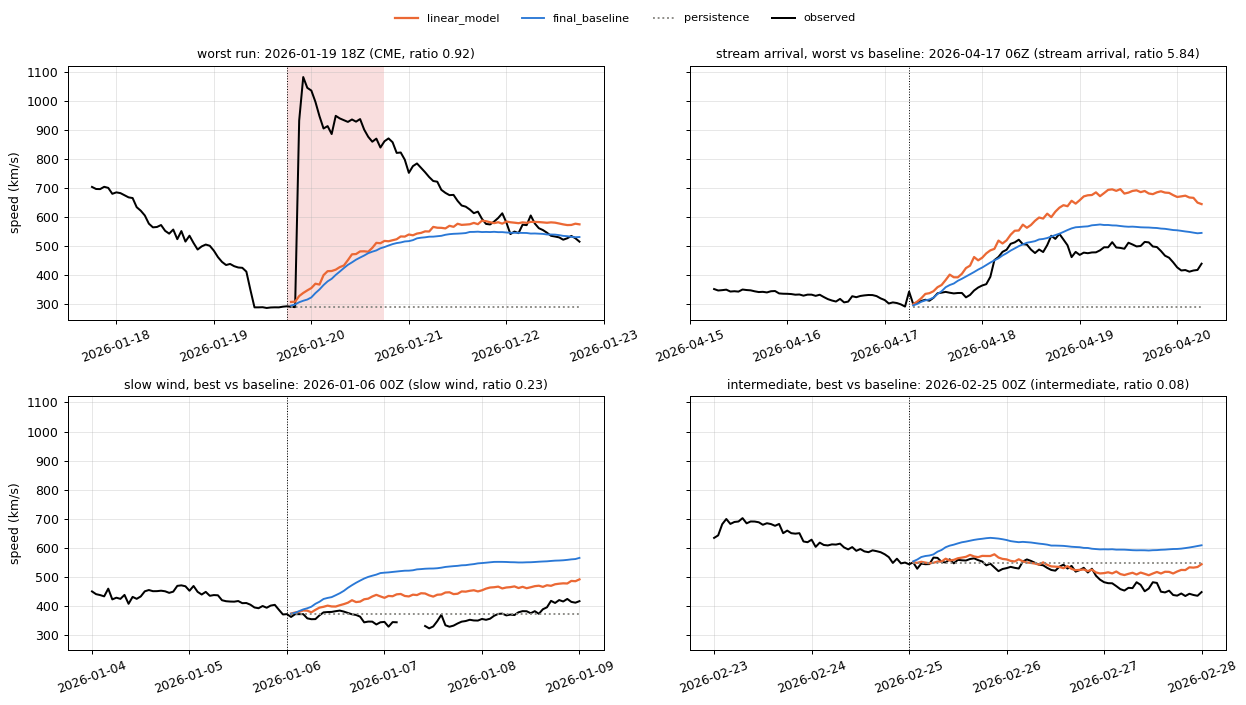

In [18]:
picks = [("worst run", cols["linear"].idxmax())]
d = cols[(regime == "stream arrival").to_numpy()]
picks.append(("stream arrival, worst vs baseline", d["linear / baseline"].idxmax()))
for g in ("slow wind", "intermediate"):
    d = cols[(regime == g).to_numpy()]
    picks.append((f"{g}, best vs baseline", d["linear / baseline"].idxmin()))

fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharey=True)
for ax, (label, t0) in zip(axes.flat, picks, strict=True):
    k = t0s.get_loc(t0)
    hist = series[t0 - pd.Timedelta(hours=48): t0 + pd.Timedelta(hours=HORIZON)]
    ax.plot(hist.index, hist, color="k", lw=1.6)
    times = t0 + pd.to_timedelta(lead, unit="h")
    for m in MODELS:
        ax.plot(times, forecasts[m][k], **STYLE[m])
    ax.axvline(t0, color="k", lw=0.8, ls=":")
    shade(ax, hist.index[0], hist.index[-1], gap=False)
    ax.set_title(f"{label}: {t0:%Y-%m-%d %H}Z ({regime.iloc[k]}, "
                 f"ratio {vs_base.iloc[k]:.2f})", fontsize=10)
    ax.tick_params(axis="x", labelrotation=20)
for ax in axes[:, 0]:
    ax.set_ylabel("speed (km/s)")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=1.6), "observed")])

## 7. Findings

Eval year 2025-10-20 → 2026-10-20, 1,448 runs. The shipped model has despiking, the
coronal-hole submodel, and four regressors from the re-selection. The first fit's scores come from
`docs/linear_model.md`.

### (i) Overall: better than the baseline on everything but p90

| | Linear model | First fit | Final baseline | Change vs baseline |
|---|---|---|---|---|
| Pooled TIMSE | 4.74 × 10⁷ | 4.75 × 10⁷ | 5.58 × 10⁷ | −15% |
| Per-run mean | 2.37 × 10⁶ | 2.44 × 10⁶ | 2.59 × 10⁶ | −8% |
| Per-run median | 6.76 × 10⁵ | 7.21 × 10⁵ | 8.45 × 10⁵ | −20% |
| Per-run p90 | 3.76 × 10⁶ | 4.00 × 10⁶ | 3.21 × 10⁶ | +17% |
| RMSE (km/s) | 102 | 106 | 110 | −7% |
| Runs won against the baseline | 64% | 56% | | |

- **The per-run quantiles are 10–22% lower than the baseline's at every level except p90** (section 1). The p99 is 20% lower. The worse p90 is a band of mid-sized losses, almost all stream arrivals.
- **The gain is broader than in the first fit:**
  - **Less dependent on one event:** the CME of 17–22 January 2026 accounts for 49% of the drop in the per-run total, down from 69%. Without those six days, the per-run mean is 6% below the baseline's (first fit: 2.5%).
  - **More months won:** the model wins more runs than it loses in 11 of 13 months (one is a tie).
  - **Quiet wind:** the no-CME runs now gain on the per-run mean too, 3% below the baseline (the first fit was 2% worse). Their pooled TIMSE is still 7% above the baseline's, because of the stream arrivals.

### (ii) By regime: everything improves except stream arrivals

| Regime | Runs | Median linear / baseline | Linear wins | Pooled linear / baseline | Share of the total change |
|---|---|---|---|---|---|
| CME | 295 | 0.89 | 66% | 0.85 | −84% |
| possible CME | 81 | 0.82 | 70% | 0.94 | −3% |
| stream arrival | 304 | **1.12** | **41%** | **1.18** | **+41%** |
| fast stream | 105 | 0.98 | 51% | 0.99 | −6% |
| slow wind | 186 | **0.62** | **83%** | 0.69 | −15% |
| intermediate | 477 | **0.76** | 73% | 0.60 | −32% |

- **Every regime except stream arrivals is at or below the baseline,** and every one improved on the first fit. Possible-CME runs improved most, from a median ratio of 1.02 to 0.82.
- **Stream arrivals are still lost more often than won.** Their extra cost is 41% of the year's net gain, down from 74% in the first fit.

### (iii) The quiet-wind over-forecast: smaller at short leads, unchanged at 72 h

- **At 24 h the bias is about a fifth smaller:** −77 km/s in slow wind against −98 for the baseline, and −61 against −75 in intermediate wind (section 3).
- **At 72 h it is about the same:** −152 against −166 in slow wind, −154 against −159 in intermediate.
- **The forecast floor barely moves:** at 72 h the 1st percentile is 435 km/s (baseline 447) and the median 563 (567), against an observed median of 448.
- **The regressors help only a little here:** they pull slow-wind forecasts down by 11–16 km/s on average (section 5.2).
- **CME runs:** the over-forecast at 72 h is now larger than the baseline's (−76 against −58 km/s), though the per-run scores are better.

### (iv) Stream arrivals: earlier at 1–2 days, still level-driven

- **About 1 day ahead,** forecasts reproduce 39% of the observed rise (baseline 27%). At 2 days it is 13% (4%), at 3 days 2% (2%) (section 4).
- **Before an arrival the model sits lower** than the baseline, so the bias at 24 h in arrival runs is −32 km/s against −49.
- **The worst losses are arrivals that don't match the coronal hole:**
  - 16–17 April 2026: the year's largest central-meridian hole (strip area 0.37) produced a 542 km/s stream. The model forecast about 650 km/s and scored up to 5.8× the baseline.
  - 12–13 March 2026: no image, so the submodel forecast without a hole.
  - 19 December 2025 and 3 October 2026: a small hole followed by a strong stream.

### (v) The regressors

- **Speed terms:** the weight on the last speed falls to about −0.6 by 48–60 h, so the forecast moves 60% of the way from persistence towards the climatology; the 27-day recurrence adds 0.15–0.29; the 13.5-day term is near zero.
- **Coronal-hole strip:** the largest effect, +24 to +30 km/s per standard deviation at 40–72 h, matching the 2–3-day travel time.
- **Density (+10–19 km/s) and flares (+6–14 km/s)** push the forecast up.
- **Field variability:** small in the main model. In the submodel it takes over part of the coronal-hole role (−10 to −15 km/s per standard deviation at 30–70 h; dashed lines in 5.1).
- **Ablation** (section 5.3):
  - **Coronal-hole strip** at its median: per-run mean 19% worse, pooled 34% worse, but the **median run 22% better**. It saves the big runs at the cost of the typical one, more so than in the first fit.
  - **Flares:** help everywhere (4–6%).
  - **Density and field variability:** help the median (2–5%), but are neutral to slightly negative on pooled TIMSE (density −2%).
  - **All four at their medians:** per-run mean 15% above the baseline, median 11% better than the full model. The quiet-wind gain on typical runs comes from the speed terms; the regressors bring the gain on the mean.
  - **The submodel for every run:** costs only 7% on the per-run mean (still 2% below the baseline). It is a reasonable stand-in when the image is missing.
- **Coronal-hole size** (section 5.4):

  | Strip area | Median linear / baseline | Linear wins |
  |---|---|---|
  | smallest quarter | 0.61 | 84% |
  | 2nd quarter | 0.74 | 74% |
  | 3rd quarter | 0.93 | 58% |
  | largest quarter | **1.10** | **45%** |

  - In the largest quarter it over-forecasts at 72 h more than the baseline (−114 against −71 km/s). The linear term assumes a large hole always brings a fast stream to Earth.
- **The coronal-hole gap no longer costs the gain:** on the 279 submodel runs the median ratio is 0.88 and the model wins 61%. With median imputation in the first fit it was 0.99 and 51%.

### (vi) Despiking, and what is left

- **4 isolated glitch hours** in the training years were removed (634, 1,087, 521 and 598 km/s, each between hours of 300–500 km/s; section 5.5).
- **The largest weight any single run-hour gets** fell from 2.1% to 0.8%, and the coefficients are 2.5–5× smoother.
- **A smaller six-lead pattern remains** (the flare coefficient in 5.1; jitter in some forecasts in section 1). It is structural: with 6-hourly runs, lead k is fitted only on target hours at one time of day modulo 6, so neighbouring leads never share data.

### What this means for the next model (XGBoost)

1. **Train on hourly forecast times,** not just the 6-hourly live schedule. Every lead then sees every hour, which removes the remaining six-lead pattern and gives 6× more (correlated) runs. Folds and scoring stay on the 6-hourly schedule.
2. **Let the coronal-hole effect level off.** Its largest values over-forecast: trees can learn that a large hole plus a slow current speed (or other context) does not always mean a fast stream.
3. **Stream arrivals are the main remaining loss** (+41% of the net change), and the quiet-wind level at 72 h is unchanged. Both need inputs or interactions that say when a stream will, or won't, arrive. Candidates: the eastern-strip regressor, the hole's latitude, and recurrence agreeing with the hole.
4. **Handle missing images natively.** XGBoost routes missing values itself, which replaces the submodel.
5. **Keep the data fixes** (despiking, image fallback) for every model.

### Caveats

- **One year:** these are eval-year results. The fixes and the re-selection were chosen on the training folds. The eval year has now been scored twice: once for the first fit, and once for this model after the re-selection. The ablation, the coronal-hole split and the first-fit comparison are analyses, not choices.
- **Regimes** come from CMEs identified in the in-situ data and use the observed future speed: a diagnostic, not an input.
- **Data:** the eval speed series has its own artefacts (e.g. the frozen 290 km/s before the January 2026 shock). Both models are scored on it, as on the live leaderboard.